In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import os

In [3]:
df= pd.read_csv(r"../data/processed/credit_card_fraud_cleaned.csv")
df

,TransactionID,TransactionDate,Amount,MerchantID,TransactionType,Location,IsFraud
0,1,2024-04-03,4189.27,688,refund,San Antonio,0
1,2,2024-03-19,2659.71,109,refund,Dallas,0
2,3,2024-01-08,784.00,394,purchase,New York,0
3,4,2024-04-13,3514.40,944,purchase,Philadelphia,0
4,5,2024-07-12,369.07,475,purchase,Phoenix,0
...,...,...,...,...,...,...,...
99995,99996,2024-06-07,1057.29,289,refund,San Antonio,0
99996,99997,2023-10-22,297.25,745,refund,San Antonio,0
99997,99998,2024-05-31,3448.56,690,purchase,San Antonio,0
99998,99999,2024-10-18,3750.79,644,purchase,Philadelphia,0


In [4]:
df["TransactionDate"] = pd.to_datetime(
    df["TransactionDate"],
    errors="coerce"
)

print(df["TransactionDate"].dtype)

datetime64[ns]


In [5]:
model_df = df.copy()
model_df["TransactionMonth"] = model_df["TransactionDate"].dt.month
model_df["TransactionDay"] = model_df["TransactionDate"].dt.day
model_df["TransactionDayOfWeek"] = (
    model_df["TransactionDate"].dt.dayofweek
)

model_df = model_df.sort_values("TransactionDate").reset_index(drop=True)

print("Earliest transaction:", model_df["TransactionDate"].min())
print("Latest transaction:", model_df["TransactionDate"].max())

Earliest transaction: 2023-10-21 00:00:00
Latest transaction: 2024-10-21 00:00:00


In [6]:
display(model_df.head())

,TransactionID,TransactionDate,Amount,MerchantID,TransactionType,Location,IsFraud,TransactionMonth,TransactionDay,TransactionDayOfWeek
0,55990,2023-10-21,127.49,546,refund,San Antonio,0,10,21,5
1,75526,2023-10-21,1506.60,241,refund,San Jose,0,10,21,5
2,1468,2023-10-21,4612.80,381,purchase,Dallas,0,10,21,5
3,43811,2023-10-21,4035.54,498,refund,Houston,0,10,21,5
4,39412,2023-10-21,1879.75,576,refund,New York,0,10,21,5


In [7]:
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining date range:")
print(train_df["TransactionDate"].min(), "to",
      train_df["TransactionDate"].max())

print("\nTesting date range:")
print(test_df["TransactionDate"].min(), "to",
      test_df["TransactionDate"].max())

Training shape: (80000, 10)
Testing shape: (20000, 10)

Training date range:
2023-10-21 00:00:00 to 2024-08-08 00:00:00

Testing date range:
2024-08-08 00:00:00 to 2024-10-21 00:00:00


In [8]:
print("Training fraud distribution:")
print(train_df["IsFraud"].value_counts())
print((train_df["IsFraud"].value_counts(normalize=True) * 100).round(2))

Training fraud distribution:
IsFraud
0    79203
1      797
Name: count, dtype: int64
IsFraud
0    99.0
1     1.0
Name: proportion, dtype: float64


In [9]:
print("\nTesting fraud distribution:")
print(test_df["IsFraud"].value_counts())
print((test_df["IsFraud"].value_counts(normalize=True) * 100).round(2))


Testing fraud distribution:
IsFraud
0    19797
1      203
Name: count, dtype: int64
IsFraud
0    98.98
1     1.01
Name: proportion, dtype: float64


In [10]:
split_date = model_df["TransactionDate"].sort_values().iloc[
    int(len(model_df) * 0.80)
]

train_df = model_df[
    model_df["TransactionDate"] < split_date
].copy()

test_df = model_df[
    model_df["TransactionDate"] >= split_date
].copy()

print("Split date:", split_date)

print("\nTraining shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nLast training date:", train_df["TransactionDate"].max())
print("First testing date:", test_df["TransactionDate"].min())

Split date: 2024-08-08 00:00:00

Training shape: (79741, 10)
Testing shape: (20259, 10)

Last training date: 2024-08-07 00:00:00
First testing date: 2024-08-08 00:00:00


In [11]:
feature_columns = [
    "Amount",
    "MerchantID",
    "TransactionType",
    "Location",
    "TransactionMonth",
    "TransactionDay",
    "TransactionDayOfWeek"
]

X_train = train_df[feature_columns]
y_train = train_df["IsFraud"]

X_test = test_df[feature_columns]
y_test = test_df["IsFraud"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))

X_train: (79741, 7)
X_test: (20259, 7)

Training fraud cases: 794
Testing fraud cases: 206


In [12]:
feature_columns = [
    "Amount",
    "MerchantID",
    "TransactionType",
    "Location",
    "TransactionMonth",
    "TransactionDay",
    "TransactionDayOfWeek"
]
X_train = train_df[feature_columns]
y_train = train_df["IsFraud"]

X_test = test_df[feature_columns]
y_test = test_df["IsFraud"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))

X_train: (79741, 7)
X_test: (20259, 7)

Training fraud cases: 794
Testing fraud cases: 206


In [13]:
numeric_features = [
    "Amount",
    "MerchantID",
    "TransactionMonth",
    "TransactionDay",
    "TransactionDayOfWeek"
]

categorical_features = [
    "TransactionType",
    "Location"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### ML MODEL COMPARISION FOR SELECT BEST MODEL
## logisticRegression

In [14]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [15]:
logistic_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [16]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 fraud probabilities:")
print(y_prob[:10].round(3))

Predictions generated successfully!

First 10 actual labels:
[0, 0, 0, 0, 0, 0, 0, 0, 1, 0]

First 10 predicted labels:
[0 0 1 1 0 0 0 0 1 0]

First 10 fraud probabilities:
[0.473 0.474 0.515 0.501 0.495 0.449 0.448 0.497 0.565 0.435]


Classification Report:

              precision    recall  f1-score   support

      Normal       0.99      0.69      0.81     20053
       Fraud       0.01      0.24      0.01       206

    accuracy                           0.68     20259
   macro avg       0.50      0.46      0.41     20259
weighted avg       0.98      0.68      0.80     20259

Confusion Matrix:
[[13759  6294]
 [  157    49]]


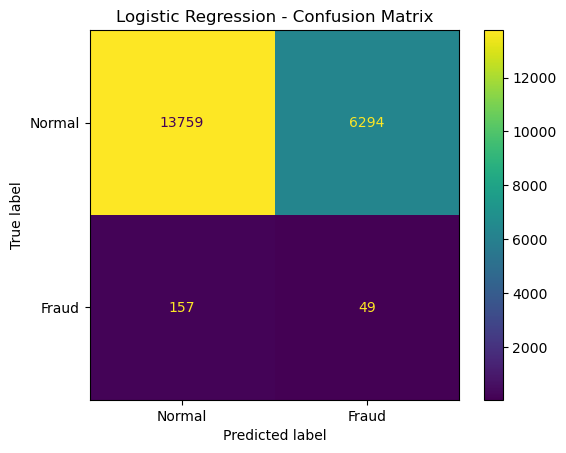

In [17]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

display_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)

display_plot.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [18]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_test, y_prob)

print("PR-AUC (Average Precision):", round(pr_auc, 4))

PR-AUC (Average Precision): 0.009


# Random Forest

In [19]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [20]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [21]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Classification Report:\n")

print(
    classification_report(
        y_test,
        rf_pred,
        labels=[0, 1],
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred, labels=[0, 1]))

rf_pr_auc = average_precision_score(y_test, rf_prob)

print("\nRandom Forest PR-AUC:", round(rf_pr_auc, 4))

Random Forest Classification Report:

              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99     20053
       Fraud       0.00      0.00      0.00       206

    accuracy                           0.99     20259
   macro avg       0.49      0.50      0.50     20259
weighted avg       0.98      0.99      0.98     20259

Random Forest Confusion Matrix:
[[20053     0]
 [  206     0]]

Random Forest PR-AUC: 0.0102


In [22]:

import pandas as pd
import numpy as np

print("Prediction probability summary:")
print(pd.Series(rf_prob).describe())

print("\nFraud probability ranges:")
print("Minimum:", round(rf_prob.min(), 4))
print("Maximum:", round(rf_prob.max(), 4))
print("Mean:", round(rf_prob.mean(), 4))

print("\nNumber of predictions at different thresholds:")
for threshold in [0.01, 0.02, 0.05, 0.10, 0.20, 0.30, 0.50]:
    predicted_fraud = (rf_prob >= threshold).sum()
    print(f"Threshold {threshold:.2f}: {predicted_fraud} transactions flagged")


Prediction probability summary:
count    20259.000000
mean         0.217747
std          0.073802
min          0.018438
25%          0.163530
50%          0.216332
75%          0.269334
max          0.497946
dtype: float64

Fraud probability ranges:
Minimum: 0.0184
Maximum: 0.4979
Mean: 0.2177

Number of predictions at different thresholds:
Threshold 0.01: 20259 transactions flagged
Threshold 0.02: 20258 transactions flagged
Threshold 0.05: 20203 transactions flagged
Threshold 0.10: 19229 transactions flagged
Threshold 0.20: 11793 transactions flagged
Threshold 0.30: 2870 transactions flagged
Threshold 0.50: 0 transactions flagged


In [23]:

from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]

results = []

for threshold in thresholds:
    pred = (rf_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Fraud Alerts": int(pred.sum()),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(4).to_string(index=False))


 Threshold  Fraud Alerts  Precision  Recall  F1-Score
      0.05         20203     0.0102  1.0000    0.0202
      0.10         19229     0.0102  0.9563    0.0203
      0.15         16283     0.0101  0.7961    0.0199
      0.20         11793     0.0097  0.5534    0.0190
      0.25          6749     0.0096  0.3155    0.0187
      0.30          2870     0.0087  0.1214    0.0163
      0.35           793     0.0113  0.0437    0.0180
      0.40           135     0.0074  0.0049    0.0059
      0.45            15     0.0667  0.0049    0.0090


In [24]:

print("Random Forest:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("\nLogistic Regression:")
print(classification_report(y_test, y_pred, zero_division=0))


Random Forest:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     20053
           1       0.00      0.00      0.00       206

    accuracy                           0.99     20259
   macro avg       0.49      0.50      0.50     20259
weighted avg       0.98      0.99      0.98     20259


Logistic Regression:
              precision    recall  f1-score   support

           0       0.99      0.69      0.81     20053
           1       0.01      0.24      0.01       206

    accuracy                           0.68     20259
   macro avg       0.50      0.46      0.41     20259
weighted avg       0.98      0.68      0.80     20259



In [25]:
evaluation_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Fraud_Precision": precision_score(
            y_test, rf_pred, zero_division=0
        ),
        "Fraud_Recall": recall_score(
            y_test, rf_pred, zero_division=0
        ),
        "Fraud_F1": f1_score(
            y_test, rf_pred, zero_division=0
        ),
        "PR_AUC": average_precision_score(y_test, rf_prob)
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Fraud_Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Fraud_Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Fraud_F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "PR_AUC": average_precision_score(y_test, y_prob)
    }
])

display(evaluation_results.round(4))


,Model,Accuracy,Fraud_Precision,Fraud_Recall,Fraud_F1,PR_AUC
0,Random Forest,0.9898,0.0000,0.0000,0.000,0.0102
1,Logistic Regression,0.6816,0.0077,0.2379,0.015,0.0090


### Fraud Prediction And Risk Scoring

In [26]:
fraud_predictions = X_test.copy()

fraud_predictions["Actual_Fraud"] = y_test.to_numpy()
fraud_predictions["Fraud_Probability"] = rf_prob

fraud_predictions["Risk_Level"] = pd.cut(
    fraud_predictions["Fraud_Probability"],
    bins=[-float("inf"), 0.10, 0.30, float("inf")],
    labels=["Low", "Medium", "High"]
)

display(fraud_predictions.head(10))


,Amount,MerchantID,TransactionType,Location,TransactionMonth,TransactionDay,TransactionDayOfWeek,Actual_Fraud,Fraud_Probability,Risk_Level
79741,3184.45,476,purchase,San Antonio,8,8,3,0,0.329571,High
79742,1947.71,628,purchase,Chicago,8,8,3,0,0.338072,High
79743,3899.16,649,refund,Houston,8,8,3,0,0.310024,High
79744,4867.68,414,purchase,Los Angeles,8,8,3,0,0.241670,Medium
79745,2589.02,579,purchase,Los Angeles,8,8,3,0,0.346985,High
79746,4604.14,73,refund,Chicago,8,8,3,0,0.142990,Medium
79747,432.23,301,refund,Phoenix,8,8,3,0,0.250958,Medium
79748,2486.90,480,purchase,Dallas,8,8,3,0,0.323962,High
79749,4206.30,877,refund,New York,8,8,3,1,0.465882,High
79750,288.42,318,refund,San Antonio,8,8,3,0,0.182083,Medium


In [27]:
fraud_predictions.insert(
    0, "TransactionID",
    test_df["TransactionID"].to_numpy()
)

fraud_predictions.insert(
    1, "TransactionDate",
    test_df["TransactionDate"].to_numpy()
)

display(fraud_predictions.head(10))


,TransactionID,TransactionDate,Amount,MerchantID,TransactionType,Location,TransactionMonth,TransactionDay,TransactionDayOfWeek,Actual_Fraud,Fraud_Probability,Risk_Level
79741,3030,2024-08-08,3184.45,476,purchase,San Antonio,8,8,3,0,0.329571,High
79742,81939,2024-08-08,1947.71,628,purchase,Chicago,8,8,3,0,0.338072,High
79743,3243,2024-08-08,3899.16,649,refund,Houston,8,8,3,0,0.310024,High
79744,58390,2024-08-08,4867.68,414,purchase,Los Angeles,8,8,3,0,0.241670,Medium
79745,44798,2024-08-08,2589.02,579,purchase,Los Angeles,8,8,3,0,0.346985,High
79746,99811,2024-08-08,4604.14,73,refund,Chicago,8,8,3,0,0.142990,Medium
79747,25909,2024-08-08,432.23,301,refund,Phoenix,8,8,3,0,0.250958,Medium
79748,3435,2024-08-08,2486.90,480,purchase,Dallas,8,8,3,0,0.323962,High
79749,23921,2024-08-08,4206.30,877,refund,New York,8,8,3,1,0.465882,High
79750,45049,2024-08-08,288.42,318,refund,San Antonio,8,8,3,0,0.182083,Medium


In [28]:
print("Prediction table shape:", fraud_predictions.shape)

print("\nColumn names:")
print(fraud_predictions.columns.tolist())

print("\nRisk level counts:")
display(
    fraud_predictions["Risk_Level"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
    .rename_axis("Risk_Level")
    .reset_index(name="Transaction_Count")
)

print("\nAverage predicted fraud probability:")
print(
    round(fraud_predictions["Fraud_Probability"].mean(), 4)
)


Prediction table shape: (20259, 12)

Column names:
['TransactionID', 'TransactionDate', 'Amount', 'MerchantID', 'TransactionType', 'Location', 'TransactionMonth', 'TransactionDay', 'TransactionDayOfWeek', 'Actual_Fraud', 'Fraud_Probability', 'Risk_Level']

Risk level counts:


,Risk_Level,Transaction_Count
0,Low,1030
1,Medium,16359
2,High,2870



Average predicted fraud probability:
0.2177


In [29]:
os.makedirs("../data/processed", exist_ok=True)

prediction_path = "../data/processed/fraud_predictions.csv"

fraud_predictions.to_csv(prediction_path, index=False)

print("Prediction file saved successfully!")
print("File path:", os.path.abspath(prediction_path))
print("Rows saved:", len(fraud_predictions))


Prediction file saved successfully!
File path: C:\Users\prasa\fraud_detection_project\data\processed\fraud_predictions.csv
Rows saved: 20259


In [30]:
import joblib
import os

# Create the models folder
os.makedirs("../models", exist_ok=True)

# Save the trained Random Forest pipeline
model_path = "../models/random_forest_model.joblib"

joblib.dump(rf_model, model_path)

print("Model saved successfully!")
print("Saved location:", os.path.abspath(model_path))

Model saved successfully!
Saved location: C:\Users\prasa\fraud_detection_project\models\random_forest_model.joblib


In [31]:
import joblib

# Load the saved model
loaded_model = joblib.load(
    "../models/random_forest_model.joblib"
)

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

# Test predictions on existing test data
sample_transactions = X_test.head(5)

sample_probabilities = loaded_model.predict_proba(
    sample_transactions
)[:, 1]

print("\nFraud probabilities:")
print(sample_probabilities)

Model loaded successfully!
Model type: Pipeline

Fraud probabilities:
[0.32957127 0.33807162 0.31002443 0.24167016 0.34698535]
